# Customer Segmentation for an Online Retailer (RFM + K-Means)

**Questions**
1. How concentrated is revenue among customers?
2. Can customers be grouped into a small number of segments based on how recently, how often and how much they buy?
3. What should marketing do differently for each segment?

**Data:** the [Online Retail dataset](https://archive.ics.uci.edu/dataset/352/online+retail) (Chen, 2015) from the UCI Machine Learning Repository: every transaction from a UK-based online gift retailer between 1 December 2010 and 9 December 2011 (541,909 invoice lines).

**Tools:** Python, pandas, matplotlib, scikit-learn.

## 1. Setup and data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from pathlib import Path

DEEP, DARK, MID, LIGHT, SOFT, PLUM = "#880E4F", "#D81B60", "#F48FB1", "#F8BBD0", "#E8A0BF", "#AD1457"   # pink palette
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold", "svg.fonttype": "none"})
Path("images").mkdir(exist_ok=True)

raw = pd.read_csv("data/online_retail.csv.gz", dtype={"InvoiceNo": str, "StockCode": str, "CustomerID": "Int64"})
raw["InvoiceDate"] = pd.to_datetime(raw["InvoiceDate"], format="%m/%d/%Y %H:%M")
print(raw.shape)
print(raw.isna().sum().to_string())
raw.head()

(541909, 8)
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom


Each row is one product line on an invoice. Three things need cleaning before any customer analysis:

- **Missing customer IDs.** About a quarter of rows have no `CustomerID` (guest checkouts), so they cannot be assigned to a customer.
- **Cancellations.** Invoice numbers starting with `C` are cancelled orders, with negative quantities.
- **Non-sales rows.** A few rows have a zero or negative price or quantity (adjustments, samples, bad debt).

In [2]:
cancel = raw.InvoiceNo.str.startswith("C")
print(f"rows without a customer ID: {raw.CustomerID.isna().sum():,} ({raw.CustomerID.isna().mean():.1%})")
print(f"cancellation rows:          {cancel.sum():,} ({cancel.mean():.1%})")
print(f"rows with price <= 0:       {(raw.UnitPrice <= 0).sum():,}")

df = raw[raw.CustomerID.notna() & ~cancel & (raw.Quantity > 0) & (raw.UnitPrice > 0)].copy()
df["Revenue"] = df.Quantity * df.UnitPrice
print(f"\nclean rows: {len(df):,} of {len(raw):,} ({len(df)/len(raw):.1%})")
print(f"customers:  {df.CustomerID.nunique():,}")
print(f"orders:     {df.InvoiceNo.nunique():,}")
print(f"revenue:    £{df.Revenue.sum():,.0f}")
print(f"period:     {df.InvoiceDate.min():%d %b %Y} to {df.InvoiceDate.max():%d %b %Y}")
print(f"UK share of customers: {(df.groupby('CustomerID').Country.first() == 'United Kingdom').mean():.1%}")
print(f"UK share of revenue:   {df.loc[df.Country == 'United Kingdom', 'Revenue'].sum() / df.Revenue.sum():.1%}")

rows without a customer ID: 135,080 (24.9%)
cancellation rows:          9,288 (1.7%)
rows with price <= 0:       2,517

clean rows: 397,884 of 541,909 (73.4%)
customers:  4,338
orders:     18,532
revenue:    £8,911,408
period:     01 Dec 2010 to 09 Dec 2011


UK share of customers: 90.4%
UK share of revenue:   82.0%


## 2. Sales over time

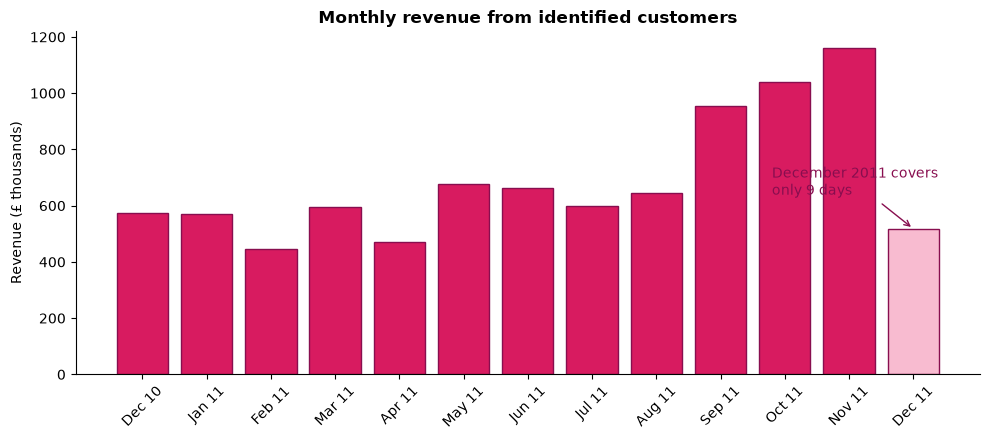

InvoiceDate
2010-12-01     573.0
2011-01-01     569.0
2011-02-01     447.0
2011-03-01     596.0
2011-04-01     469.0
2011-05-01     679.0
2011-06-01     661.0
2011-07-01     600.0
2011-08-01     645.0
2011-09-01     953.0
2011-10-01    1039.0
2011-11-01    1162.0
2011-12-01     518.0
Freq: MS


In [3]:
monthly = df.set_index("InvoiceDate").Revenue.resample("MS").sum() / 1000
fig, ax = plt.subplots()
colors = [LIGHT if m == monthly.index[-1] else DARK for m in monthly.index]
ax.bar([m.strftime("%b %y") for m in monthly.index], monthly.values, color=colors, edgecolor=DEEP)
ax.set_ylabel("Revenue (£ thousands)")
ax.set_title("Monthly revenue from identified customers")
ax.annotate("December 2011 covers\nonly 9 days", xy=(len(monthly) - 1, monthly.iloc[-1]),
            xytext=(len(monthly) - 3.2, monthly.max() * 0.55), arrowprops={"arrowstyle": "->", "color": DEEP}, color=DEEP)
plt.xticks(rotation=45)
plt.tight_layout(); plt.savefig("images/monthly_revenue.svg"); plt.show()
print(monthly.round(0).to_string())

Revenue is fairly flat at around £450k to £680k a month until August, then climbs sharply: September (£953k), October (£1.04m) and November (£1.16m) are the three biggest months. This is a gift retailer, and many of its customers are wholesalers stocking up before Christmas. December 2011 looks low only because the data stops on 9 December.

## 3. Building the RFM table

RFM summarises each customer with three numbers:

- **Recency:** days since their last order (lower is better)
- **Frequency:** number of separate orders
- **Monetary:** total amount spent

Recency is measured from the day after the last transaction in the data.

In [4]:
snapshot = df.InvoiceDate.max().normalize() + pd.Timedelta(days=1)
rfm = df.groupby("CustomerID").agg(recency=("InvoiceDate", lambda d: (snapshot - d.max().normalize()).days),
                                   frequency=("InvoiceNo", "nunique"),
                                   monetary=("Revenue", "sum"))
print(rfm.describe(percentiles=[.25, .5, .75, .95]).round(1).to_string())
print(f"\ncustomers with exactly one order: {(rfm.frequency == 1).mean():.1%}")

       recency  frequency  monetary
count   4338.0     4338.0    4338.0
mean      93.1        4.3    2054.3
std      100.0        7.7    8989.2
min        1.0        1.0       3.8
25%       18.0        1.0     307.4
50%       51.0        2.0     674.5
75%      142.8        5.0    1661.7
95%      312.0       13.0    5841.8
max      374.0      209.0  280206.0

customers with exactly one order: 34.4%


top   1% of customers -> 31.8% of revenue
top   5% of customers -> 50.3% of revenue
top  10% of customers -> 61.3% of revenue
top  20% of customers -> 74.6% of revenue
top  50% of customers -> 92.2% of revenue


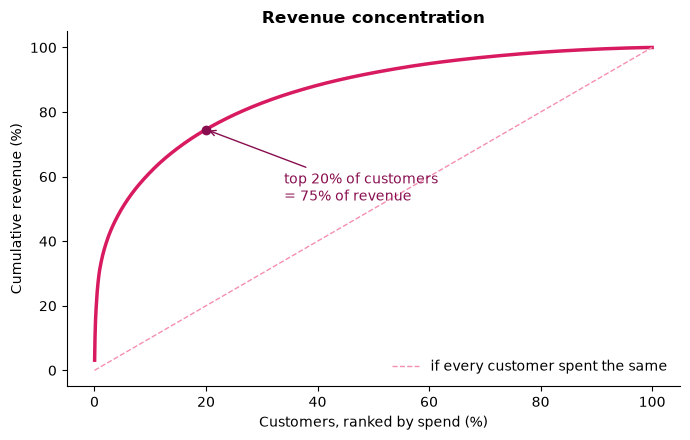

In [5]:
order = rfm.monetary.sort_values(ascending=False)
cum = order.cumsum() / order.sum()
share = np.arange(1, len(order) + 1) / len(order)
for p in (0.01, 0.05, 0.10, 0.20, 0.50):
    print(f"top {p:>4.0%} of customers -> {cum.iloc[int(len(order) * p) - 1]:.1%} of revenue")

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(share * 100, cum * 100, color=DARK, lw=2.5)
ax.plot([0, 100], [0, 100], color=MID, ls="--", lw=1, label="if every customer spent the same")
top20 = cum.iloc[int(len(order) * 0.2) - 1] * 100
ax.scatter([20], [top20], color=DEEP, zorder=3)
ax.annotate(f"top 20% of customers\n= {top20:.0f}% of revenue", xy=(20, top20), xytext=(34, top20 - 22),
            arrowprops={"arrowstyle": "->", "color": DEEP}, color=DEEP)
ax.set_xlabel("Customers, ranked by spend (%)"); ax.set_ylabel("Cumulative revenue (%)")
ax.set_title("Revenue concentration"); ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.savefig("images/revenue_concentration.svg"); plt.show()

Revenue is very concentrated. The top 20% of customers bring in about 75% of revenue, and the top 1% (about 43 customers) bring in almost a third. At the other end, a third of customers (34%) ordered exactly once. Treating all 4,338 customers the same would waste effort, which is the case for segmenting them.

## 4. Preparing the features

All three variables are heavily right-skewed: most customers order once or twice and spend a few hundred pounds, while a handful spend tens of thousands. K-means uses distances, so without a transformation those few customers would dominate. I take logs and then standardise each variable to mean 0 and standard deviation 1.

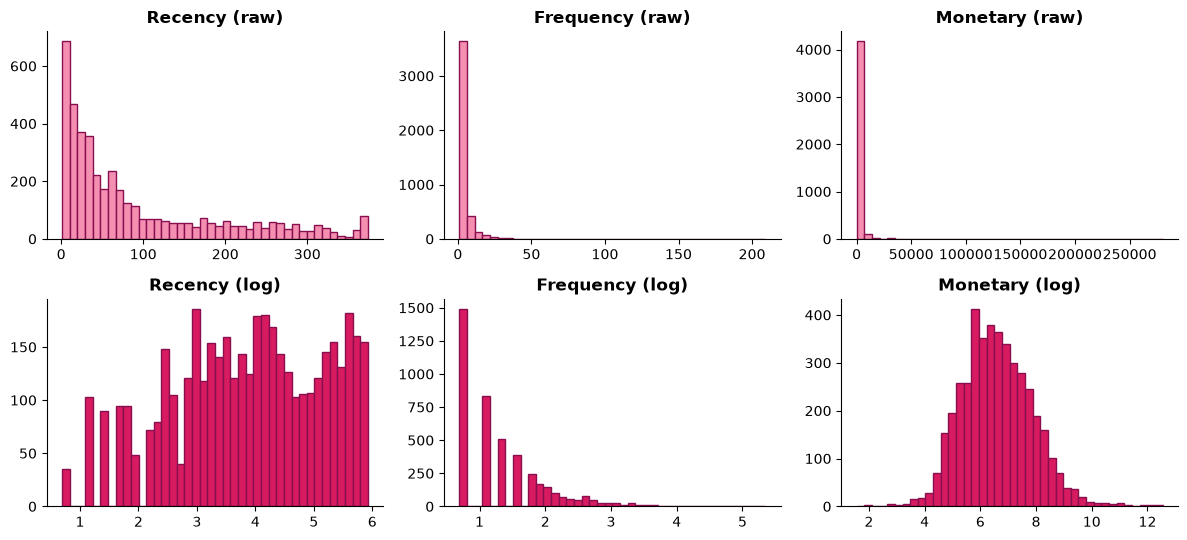

skewness, raw: {'recency': 1.2, 'frequency': 12.1, 'monetary': 19.3}
skewness, log: {'recency': -0.3, 'frequency': 1.2, 'monetary': 0.4}


In [6]:
fig, axes = plt.subplots(2, 3, figsize=(12, 5.5))
for j, col in enumerate(["recency", "frequency", "monetary"]):
    axes[0, j].hist(rfm[col], bins=40, color=MID, edgecolor=DEEP)
    axes[0, j].set_title(f"{col.title()} (raw)")
    axes[1, j].hist(np.log1p(rfm[col]), bins=40, color=DARK, edgecolor=DEEP)
    axes[1, j].set_title(f"{col.title()} (log)")
plt.tight_layout(); plt.savefig("images/rfm_distributions.svg"); plt.show()
print("skewness, raw:", rfm.skew().round(1).to_dict())
print("skewness, log:", np.log1p(rfm).skew().round(1).to_dict())

X = StandardScaler().fit_transform(np.log1p(rfm))

## 5. Choosing the number of segments

K-means needs the number of clusters in advance. I compare k = 2 to 8 on two measures: **inertia** (within-cluster spread, where I look for an "elbow") and the **silhouette score** (how well separated the clusters are, from -1 to 1).

 k  inertia  silhouette
 2   6474.0       0.433
 3   4857.0       0.336
 4   3924.0       0.336
 5   3268.0       0.318
 6   2840.0       0.316
 7   2533.0       0.310
 8   2326.0       0.302


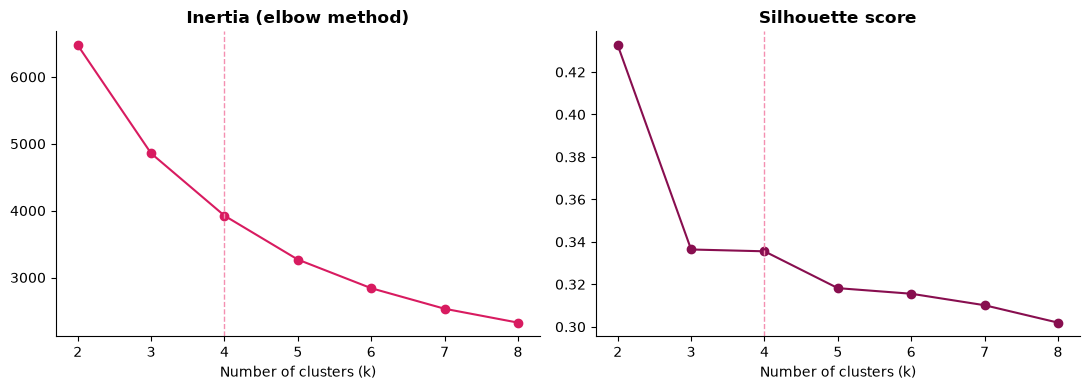

In [7]:
ks = range(2, 9)
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X, km.labels_))
print(pd.DataFrame({"k": list(ks), "inertia": np.round(inertia), "silhouette": np.round(sil, 3)}).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(list(ks), inertia, marker="o", color=DARK); axes[0].set_title("Inertia (elbow method)"); axes[0].set_xlabel("Number of clusters (k)")
axes[1].plot(list(ks), sil, marker="o", color=DEEP); axes[1].set_title("Silhouette score"); axes[1].set_xlabel("Number of clusters (k)")
for ax in axes: ax.axvline(4, color=MID, ls="--", lw=1)
plt.tight_layout(); plt.savefig("images/choosing_k.svg"); plt.show()

The silhouette score is highest at k = 2 (0.43), but two clusters only separate "high value" from "low value", which is not much use for planning campaigns. Scores for k = 3 and k = 4 are the same (0.34) and fall slowly after that, while inertia keeps dropping without a sharp elbow. I use **k = 4**: it scores as well as 3, and it splits low-spend customers into those who bought recently and those who have gone quiet, which matters for marketing.

A silhouette of 0.34 means the segments overlap at the edges. Customers sit on a continuum rather than in four tight groups, so the segments are a practical summary and not a natural law. The check below shows the assignment is stable across random starts.

In [8]:
K = 4
km = KMeans(n_clusters=K, n_init=10, random_state=42).fit(X)
rfm["cluster"] = km.labels_

# stability: do different random starts give the same segments?
ari = [adjusted_rand_score(km.labels_, KMeans(n_clusters=K, n_init=10, random_state=s).fit(X).labels_) for s in range(1, 11)]
print(f"adjusted Rand index vs 10 other random seeds: min {min(ari):.3f}, mean {np.mean(ari):.3f}")

adjusted Rand index vs 10 other random seeds: min 0.913, mean 0.942


## 6. Profiling the segments

In [9]:
profile = rfm.groupby("cluster").agg(customers=("recency", "size"), recency_median=("recency", "median"),
                                     frequency_median=("frequency", "median"), monetary_median=("monetary", "median"),
                                     monetary_mean=("monetary", "mean"), revenue=("monetary", "sum"))
profile["customer_share"] = profile.customers / profile.customers.sum()
profile["revenue_share"] = profile.revenue / profile.revenue.sum()

# name the segments from their profile, so the labels do not depend on k-means' arbitrary numbering
by_value = profile.monetary_median.sort_values(ascending=False).index.tolist()
low_two = by_value[2:]
recent_low = profile.loc[low_two, "recency_median"].idxmin()
lapsed_low = [c for c in low_two if c != recent_low][0]
names = {by_value[0]: "Champions", by_value[1]: "Loyal regulars", recent_low: "New / occasional", lapsed_low: "Lapsed"}
rfm["segment"] = rfm.cluster.map(names)
SEG_ORDER = ["Champions", "Loyal regulars", "New / occasional", "Lapsed"]
SEG_COLOR = {"Champions": DEEP, "Loyal regulars": DARK, "New / occasional": MID, "Lapsed": LIGHT}
profile.index = profile.index.map(names)
profile = profile.loc[SEG_ORDER]
print(profile.assign(customer_share=(profile.customer_share * 100).round(1), revenue_share=(profile.revenue_share * 100).round(1))
      .round({"recency_median": 0, "frequency_median": 0, "monetary_median": 0, "monetary_mean": 0, "revenue": 0}).to_string())

                  customers  recency_median  frequency_median  monetary_median  monetary_mean    revenue  customer_share  revenue_share
cluster                                                                                                                                
Champions               720             9.0              10.0           3726.0         8037.0  5786788.0            16.6           64.9
Loyal regulars         1162            54.0               4.0           1354.0         1813.0  2106281.0            26.8           23.6
New / occasional        877            19.0               2.0            451.0          527.0   462332.0            20.2            5.2
Lapsed                 1579           183.0               1.0            300.0          352.0   556007.0            36.4            6.2


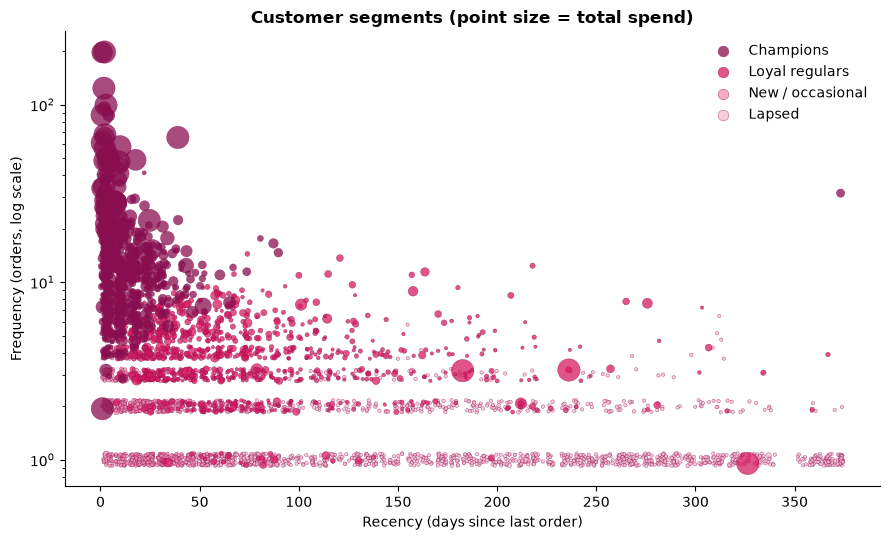

In [10]:
fig, ax = plt.subplots(figsize=(9, 5.5))
rng = np.random.default_rng(0)
for seg in SEG_ORDER[::-1]:
    g = rfm[rfm.segment == seg]
    ax.scatter(g.recency + rng.uniform(-0.4, 0.4, len(g)), g.frequency * np.exp(rng.uniform(-0.08, 0.08, len(g))),
               s=np.clip(g.monetary / 150, 6, 260), color=SEG_COLOR[seg], edgecolor=DEEP, linewidth=0.3, alpha=0.75, label=seg)
ax.set_yscale("log"); ax.set_xlabel("Recency (days since last order)"); ax.set_ylabel("Frequency (orders, log scale)")
ax.set_title("Customer segments (point size = total spend)")
handles, labels = ax.get_legend_handles_labels()
leg = ax.legend(handles[::-1], labels[::-1], frameon=False, loc="upper right")
for h in leg.legend_handles: h.set_sizes([60])
plt.tight_layout(); plt.savefig("images/segments_scatter.svg"); plt.show()

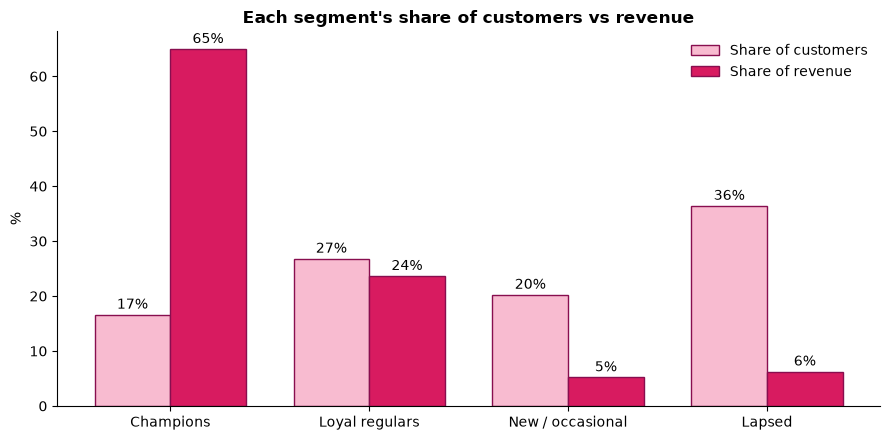

In [11]:
fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(SEG_ORDER)); w = 0.38
b1 = ax.bar(x - w / 2, profile.customer_share * 100, w, color=LIGHT, edgecolor=DEEP, label="Share of customers")
b2 = ax.bar(x + w / 2, profile.revenue_share * 100, w, color=DARK, edgecolor=DEEP, label="Share of revenue")
ax.bar_label(b1, fmt="%.0f%%", padding=2); ax.bar_label(b2, fmt="%.0f%%", padding=2)
ax.set_xticks(x, SEG_ORDER); ax.set_ylabel("%"); ax.set_title("Each segment's share of customers vs revenue"); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig("images/segment_shares.svg"); plt.show()

The four segments are easy to read:

| Segment | Customers | Typical customer | Share of revenue |
|---|---|---|---|
| **Champions** | 720 (17%) | ordered 9 days ago, 10 orders, about £3,700 spent | **65%** |
| **Loyal regulars** | 1,162 (27%) | ordered 54 days ago, 4 orders, about £1,350 spent | 24% |
| **New / occasional** | 877 (20%) | ordered 19 days ago, 2 orders, about £450 spent | 5% |
| **Lapsed** | 1,579 (36%) | ordered 183 days ago, 1 order, about £300 spent | 6% |

Champions are one in six customers and almost two thirds of revenue. Lapsed customers are the largest group by headcount but bring in only 6%.

## 7. Do the segments behave differently in other ways?

The clusters were built only from recency, frequency and spend. As a check, I look at variables the model never saw: average order value, how many different products a customer buys, and whether they are based in the UK.

In [12]:
extra = df.groupby("CustomerID").agg(products=("StockCode", "nunique"), country=("Country", "first"),
                                     first_order=("InvoiceDate", "min"))
extra["uk"] = extra.country == "United Kingdom"
extra["tenure_days"] = (snapshot - extra.first_order.dt.normalize()).dt.days
j = rfm.join(extra)
j["avg_order_value"] = j.monetary / j.frequency
check = j.groupby("segment").agg(avg_order_value=("avg_order_value", "median"), products=("products", "median"),
                                 tenure_days=("tenure_days", "median"), uk_share=("uk", "mean")).loc[SEG_ORDER]
print(check.round({"avg_order_value": 0, "products": 0, "tenure_days": 0, "uk_share": 3}).to_string())

                  avg_order_value  products  tenure_days  uk_share
segment                                                           
Champions                   369.0     116.0        358.0     0.888
Loyal regulars              360.0      59.0        279.0     0.887
New / occasional            230.0      29.0         61.0     0.917
Lapsed                      226.0      17.0        227.0     0.916


The segments differ on variables the model never saw, which suggests they capture something real:

- **Order size.** Champions and Loyal regulars spend about £360 to £370 per order, against about £230 for the two lower segments. The best customers order more often and order more each time.
- **Range.** A typical Champion has bought 116 different products, a Lapsed customer 17.
- **Tenure.** New / occasional customers placed their first order about two months before the end of the data, so most are genuinely new. Lapsed customers first ordered about seven and a half months before and did not come back.
- **Country.** The UK share is close to 90% in every segment, so the segments are not a proxy for geography.

## 8. Conclusions

**Findings**

1. Revenue is highly concentrated: the top 20% of customers generate about 75% of revenue.
2. Four segments built from recency, frequency and spend summarise the customer base well enough to act on, and the assignment is stable (adjusted Rand index 0.94 across random starts).
3. Champions (17% of customers) generate 65% of revenue. Lapsed customers (36%) generate 6%.

**What marketing could do with this**

- **Champions:** protect the relationship. Early access to the autumn range, account management for the wholesalers, and no blanket discounts, since they already buy at full frequency.
- **Loyal regulars:** the best growth opportunity. They order as much per basket as Champions but less often, so reminders timed to their usual reorder gap could move some of them up.
- **New / occasional:** a second and third order is the goal. A welcome sequence in the first 60 days, when they are still active.
- **Lapsed:** a low-cost win-back email before the September to November peak, then stop spending on those who do not respond.

**Limitations**

- A quarter of invoice lines have no customer ID and are excluded, so guest shoppers are not represented.
- The data covers one year, so customers who buy once a year (for example every November) look lapsed or new when they may be regular.
- Many customers are wholesalers, so results would not transfer directly to a consumer-only retailer.
- The clusters overlap (silhouette 0.34). Customers near a boundary could reasonably be placed in either segment.
- This is a description of past behaviour. Whether the suggested campaigns work would need to be tested, ideally with an A/B test.